In [1]:
# Se importan las librerías necesarias y se suprimen las advertencias
import pandas as pd
import matplotlib.pyplot as plt
import warnings

import mlflow
import mlflow.sklearn
import skops.io as sio
from dotenv import load_dotenv, find_dotenv

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.dummy import DummyClassifier

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore',category=FutureWarning)
warnings.filterwarnings('ignore',category=UserWarning)

# Semilla única para todos los procesos aleatorios (splits, validación cruzada y modelos)
SEED = 42

# Credenciales de MLflow (DagsHub) definidas en el archivo .env
load_dotenv(find_dotenv())

True

In [2]:
# Lectura de los datos
df = pd.read_csv('../data/processed/datos_integrados.csv', sep=';')
df.head(5)

,id_resena,id_cliente,categoria_producto,canal_compra,plataforma,calificacion,texto_resena,tiempo_respuesta_horas,problema_resuelto,reclamo_formal,...,sentimiento,edad,genero,ciudad,antiguedad_cliente_meses,longitud_resena,cantidad_palabras_resena,tiempo_respuesta_dias,cantidad_resenas_cliente,proporcion_reclamos_cliente
0,1,294,Deportes,Online,Flipkart,4,El envío fue rápido y el colchoneta llegó en p...,4.9,Sí,No,...,Positivo,18.0,Masculino,Mendoza,5,82,13,0.20,4,0.0
1,2,2376,Calzado,Online,Flipkart,4,"El sandalias es tal cual la descripción, estoy...",5.1,Sí,No,...,Positivo,18.0,Otro,San Miguel de Tucumán,61,76,13,0.21,2,0.0
2,3,1670,Electrónica,Online,Meesho,5,"Muy conforme con la compra, la calidad del par...",4.3,Sí,No,...,Positivo,29.0,Masculino,Salta,3,65,12,0.18,5,0.0
3,4,310,Hogar,Online,Falabella,3,Tuve varios problemas con el lámpara y el sopo...,6.7,Sí,No,...,Neutral,61.0,Femenino,Santa Fe,73,107,18,0.28,5,0.2
4,5,710,Deportes,Offline,Zepto,5,"Excelente botella deportiva, superó mis expect...",12.5,Sí,No,...,Positivo,46.0,Masculino,Salta,61,82,12,0.52,2,0.0


In [3]:
def reporte_descripcion_dataset(df):
    columnas = df.columns
    print("Columnas del dataset:\n")
    for col in columnas:
        print(col)
    print(f"\nCantidad de filas: {df.shape[0]}")

print("Descripción del dataset 'datos_integrados.csv':\n")
reporte_descripcion_dataset(df)

Descripción del dataset 'datos_integrados.csv':

Columnas del dataset:

id_resena
id_cliente
categoria_producto
canal_compra
plataforma
calificacion
texto_resena
tiempo_respuesta_horas
problema_resuelto
reclamo_formal
importe_compra
fecha_resena
sentimiento
edad
genero
ciudad
antiguedad_cliente_meses
longitud_resena
cantidad_palabras_resena
tiempo_respuesta_dias
cantidad_resenas_cliente
proporcion_reclamos_cliente

Cantidad de filas: 24934


### Selección de variables predictoras

Se excluyen del conjunto de predictores:

* `calificacion`: está casi determinada por el `sentimiento` (más del 97 % de coincidencia por tramo de nota), por lo que usarla produciría una fuga de información hacia la variable objetivo.
* `id_resena` e `id_cliente`: son identificadores sin significado predictivo.
* `fecha_resena`: como texto generaría cientos de columnas al codificarla, sin capacidad de generalización.

In [4]:
# Se divide el dataset en variables predictoras y variable objetivo
target = "sentimiento"
COLUMNAS_EXCLUIDAS = ["calificacion", "id_resena", "id_cliente", "fecha_resena"]

features_X = df.drop(columns=[target] + COLUMNAS_EXCLUIDAS)
labels_y = df[target]

print("Dimensiones X:", features_X.shape)
print("Dimensiones y:", labels_y.shape)

Dimensiones X: (24934, 17)
Dimensiones y: (24934,)


In [5]:
# Se genera el conjunto de entrenamiento, validación y test con estratificación

# Primero se separa el test final (10%)
X_temp, X_test, y_temp, y_test = train_test_split(
    features_X,
    labels_y,
    test_size=0.10,
    random_state=SEED,
    stratify=labels_y
)

# Luego se separan train y validation (22% del 90% es aprox. el 20% del total)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.22,
    random_state=SEED,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (17503, 17)
Validation: (4937, 17)
Test: (2494, 17)


In [6]:
# Se identifican las columnas numéricas, categóricas y de texto
# El texto de la reseña se trata por separado, ya que requiere una vectorización específica (TF-IDF)

text_col = "texto_resena"
num_cols = features_X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = [c for c in features_X.select_dtypes(include=["object", "string"]).columns if c != text_col]

print("Numéricas:", num_cols)
print("Categóricas:", cat_cols)
print("Texto:", text_col)

Numéricas: ['tiempo_respuesta_horas', 'importe_compra', 'edad', 'antiguedad_cliente_meses', 'longitud_resena', 'cantidad_palabras_resena', 'tiempo_respuesta_dias', 'cantidad_resenas_cliente', 'proporcion_reclamos_cliente']
Categóricas: ['categoria_producto', 'canal_compra', 'plataforma', 'problema_resuelto', 'reclamo_formal', 'genero', 'ciudad']
Texto: texto_resena


In [7]:
# Se verifica la distribución de la variable objetivo en el conjunto de entrenamiento
y_train.value_counts()

sentimiento
Positivo    11293
Negativo     3129
Neutral      3081
Name: count, dtype: int64

### Preprocesamiento y modelo base

Se arma un pipeline de preprocesamiento que combina variables numéricas, categóricas y el texto de la reseña, y se evalúa un modelo base (baseline) como punto de referencia mínimo.

In [8]:
# Se crea un pipeline para preprocesamiento de datos

numeric_transformer = Pipeline([
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# TfidfVectorizer recibe directamente el nombre de la columna (no una lista),
# lo que hace que ColumnTransformer le pase el texto como un arreglo unidimensional
text_transformer = TfidfVectorizer(max_features=300)

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols),
    ("text", text_transformer, text_col)
])

In [9]:
# Se crea un pipeline completo con preprocesamiento y modelo base

baseline = Pipeline([
    ("prep", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent"))
])

baseline.fit(X_train, y_train)

y_pred = baseline.predict(X_val)

print("Baseline accuracy:", accuracy_score(y_val, y_pred))

Baseline accuracy: 0.64533117277699


### Comparación de modelos con ajuste de hiperparámetros

Cada modelo se ajusta con `GridSearchCV` (validación cruzada estratificada de 5 particiones, métrica `f1_macro`) sobre el conjunto de entrenamiento. El mejor estimador de cada tipo se evalúa luego en el conjunto de validación.

In [10]:
# Se definen los modelos a evaluar junto con su grilla de hiperparámetros.
# LinearSVC se envuelve en CalibratedClassifierCV para disponer de probabilidades (necesarias para ROC-AUC).

modelos = {
    "LogisticRegression": (
        LogisticRegression(max_iter=2000, random_state=SEED),
        {"model__C": [0.1, 1, 10], "model__class_weight": [None, "balanced"]},
    ),
    "LinearSVC": (
        CalibratedClassifierCV(LinearSVC(max_iter=5000, random_state=SEED), cv=3),
        {"model__estimator__C": [0.1, 1, 10]},
    ),
    "KNN": (
        KNeighborsClassifier(),
        {"model__n_neighbors": [5, 15, 31], "model__weights": ["uniform", "distance"]},
    ),
    "DecisionTree": (
        DecisionTreeClassifier(random_state=SEED),
        {"model__max_depth": [10, 20, None], "model__min_samples_leaf": [1, 5]},
    ),
    "RandomForest": (
        RandomForestClassifier(random_state=SEED),
        {
            "model__n_estimators": [100, 300],
            "model__max_depth": [None, 20],
            "model__min_samples_leaf": [1, 5],
        },
    ),
}

In [11]:
# Se ajustan los hiperparámetros de cada modelo y se evalúa el mejor de cada tipo en validación

def calcular_metricas(modelo, X, y, prefijo):
    """ Calcula las métricas de clasificación de un modelo ajustado

    Args:
        modelo (Pipeline): Modelo ajustado con predict y predict_proba
        X (pd.DataFrame): Variables predictoras
        y (pd.Series): Variable objetivo
        prefijo (str): Prefijo para el nombre de cada métrica (por ejemplo 'val' o 'test')

    Returns:
        dict: Métricas accuracy, precision, recall, f1 (macro) y ROC-AUC (one-vs-rest, macro)
    """
    y_pred = modelo.predict(X)
    y_proba = modelo.predict_proba(X)
    return {
        f"{prefijo}_accuracy": accuracy_score(y, y_pred),
        f"{prefijo}_precision_macro": precision_score(y, y_pred, average="macro"),
        f"{prefijo}_recall_macro": recall_score(y, y_pred, average="macro"),
        f"{prefijo}_f1_macro": f1_score(y, y_pred, average="macro"),
        f"{prefijo}_roc_auc_ovr": roc_auc_score(y, y_proba, multi_class="ovr", average="macro", labels=modelo.classes_),
    }


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

busquedas = {}
resultados = []

for nombre, (estimador, grilla) in modelos.items():
    pipeline = Pipeline([
        ("prep", preprocessor),
        ("model", estimador)
    ])

    busqueda = GridSearchCV(pipeline, grilla, cv=cv, scoring="f1_macro", n_jobs=-1)
    busqueda.fit(X_train, y_train)
    busquedas[nombre] = busqueda

    resultados.append({
        "modelo": nombre,
        "cv_f1_macro": busqueda.best_score_,
        **calcular_metricas(busqueda.best_estimator_, X_val, y_val, "val"),
    })
    print(f"{nombre}: {busqueda.best_params_}")

df_resultados = pd.DataFrame(resultados).sort_values("val_f1_macro", ascending=False)
df_resultados

LogisticRegression: {'model__C': 1, 'model__class_weight': 'balanced'}


LinearSVC: {'model__estimator__C': 0.1}


KNN: {'model__n_neighbors': 5, 'model__weights': 'uniform'}


DecisionTree: {'model__max_depth': 10, 'model__min_samples_leaf': 5}


RandomForest: {'model__max_depth': 20, 'model__min_samples_leaf': 5, 'model__n_estimators': 300}


,modelo,cv_f1_macro,val_accuracy,val_precision_macro,val_recall_macro,val_f1_macro,val_roc_auc_ovr
0,LogisticRegression,0.834811,0.865910,0.815899,0.860062,0.831857,0.935923
1,LinearSVC,0.833650,0.865100,0.817071,0.856609,0.831100,0.936861
4,RandomForest,0.831066,0.862670,0.812204,0.852860,0.826803,0.935906
3,DecisionTree,0.820879,0.858821,0.813852,0.846367,0.821817,0.928669
2,KNN,0.537192,0.690298,0.584229,0.518920,0.533677,0.724576


### Registro de experimentos en MLflow

Se registra en MLflow (DagsHub) el mejor modelo de cada tipo: hiperparámetros elegidos, semilla utilizada, métricas de validación y el modelo entrenado.

In [12]:
# Se registra un run por tipo de modelo con sus hiperparámetros, la semilla y las métricas

mlflow.set_experiment("MD01-Clasificacion-Sentimiento")

run_ids = {}

# Solo se confían tipos de scikit-learn y contenedores de datos de scipy.sparse y numpy
PREFIJOS_CONFIABLES = ("sklearn.", "scipy.sparse.", "numpy.")


def tipos_confiables(modelo):
    """ Devuelve los tipos de scikit-learn, scipy.sparse y numpy que skops no reconoce como seguros por defecto

    Args:
        modelo (Pipeline): Modelo ajustado a serializar

    Returns:
        list[str]: Tipos a marcar como confiables al registrar el modelo
    """
    tipos = sio.get_untrusted_types(data=sio.dumps(modelo))
    return [tipo for tipo in tipos if tipo.startswith(PREFIJOS_CONFIABLES)]

for _, fila in df_resultados.iterrows():
    nombre = fila["modelo"]
    busqueda = busquedas[nombre]

    with mlflow.start_run(run_name=nombre) as run:
        mlflow.log_param("modelo", nombre)
        mlflow.log_param("seed", SEED)
        mlflow.log_params({clave.replace("model__", ""): valor for clave, valor in busqueda.best_params_.items()})

        mlflow.log_metric("cv_f1_macro", fila["cv_f1_macro"])
        for metrica in [c for c in df_resultados.columns if c.startswith("val_")]:
            mlflow.log_metric(metrica, fila[metrica])

        # MLflow serializa con skops: se confían solo los tipos de PREFIJOS_CONFIABLES presentes en el modelo
        mlflow.sklearn.log_model(
            busqueda.best_estimator_,
            name="modelo",
            skops_trusted_types=tipos_confiables(busqueda.best_estimator_),
        )
        run_ids[nombre] = run.info.run_id

run_ids

🏃 View run LogisticRegression at: https://dagshub.com/Andres-viu-mbid/13MBID-AZ.mlflow/#/experiments/2/runs/3a1607064644449c9218817928476438
🧪 View experiment at: https://dagshub.com/Andres-viu-mbid/13MBID-AZ.mlflow/#/experiments/2


🏃 View run LinearSVC at: https://dagshub.com/Andres-viu-mbid/13MBID-AZ.mlflow/#/experiments/2/runs/f5555ffd59af450f9e9aca9335b951c5
🧪 View experiment at: https://dagshub.com/Andres-viu-mbid/13MBID-AZ.mlflow/#/experiments/2


🏃 View run RandomForest at: https://dagshub.com/Andres-viu-mbid/13MBID-AZ.mlflow/#/experiments/2/runs/576aa53cdd57477384ad2585990284b9
🧪 View experiment at: https://dagshub.com/Andres-viu-mbid/13MBID-AZ.mlflow/#/experiments/2


🏃 View run DecisionTree at: https://dagshub.com/Andres-viu-mbid/13MBID-AZ.mlflow/#/experiments/2/runs/6649a67f72a243ecbde33ee8fd450d0a
🧪 View experiment at: https://dagshub.com/Andres-viu-mbid/13MBID-AZ.mlflow/#/experiments/2


🏃 View run KNN at: https://dagshub.com/Andres-viu-mbid/13MBID-AZ.mlflow/#/experiments/2/runs/7ce50bd304f446999249d6bb4e590e74
🧪 View experiment at: https://dagshub.com/Andres-viu-mbid/13MBID-AZ.mlflow/#/experiments/2


{'LogisticRegression': '3a1607064644449c9218817928476438',
 'LinearSVC': 'f5555ffd59af450f9e9aca9335b951c5',
 'RandomForest': '576aa53cdd57477384ad2585990284b9',
 'DecisionTree': '6649a67f72a243ecbde33ee8fd450d0a',
 'KNN': '7ce50bd304f446999249d6bb4e590e74'}

### Selección del modelo final

Se selecciona como modelo final el de mejor `f1_macro` en validación, ya ajustado sobre el conjunto de entrenamiento.

In [13]:
# Se selecciona el mejor modelo según f1_macro en validación

nombre_mejor = df_resultados.iloc[0]["modelo"]
modelo_final = busquedas[nombre_mejor].best_estimator_

print("Modelo final:", nombre_mejor)
print("Hiperparámetros:", busquedas[nombre_mejor].best_params_)

Modelo final: LogisticRegression
Hiperparámetros: {'model__C': 1, 'model__class_weight': 'balanced'}


In [14]:
# Se evalúan los resultados en el conjunto de validación

y_val_pred = modelo_final.predict(X_val)

print(classification_report(y_val, y_val_pred))

              precision    recall  f1-score   support

    Negativo       0.88      0.91      0.89       882
     Neutral       0.59      0.80      0.68       869
    Positivo       0.97      0.87      0.92      3186

    accuracy                           0.87      4937
   macro avg       0.82      0.86      0.83      4937
weighted avg       0.89      0.87      0.87      4937



In [15]:
# Se evalúan los resultados en el conjunto de test y se registran en el run del modelo final

y_test_pred = modelo_final.predict(X_test)

print(classification_report(y_test, y_test_pred))

metricas_test = calcular_metricas(modelo_final, X_test, y_test, "test")

with mlflow.start_run(run_id=run_ids[nombre_mejor]):
    mlflow.log_metrics(metricas_test)
    mlflow.set_tag("mejor_modelo", "true")

metricas_test

              precision    recall  f1-score   support

    Negativo       0.91      0.93      0.92       446
     Neutral       0.61      0.83      0.71       439
    Positivo       0.97      0.87      0.92      1609

    accuracy                           0.88      2494
   macro avg       0.83      0.88      0.85      2494
weighted avg       0.90      0.88      0.88      2494



🏃 View run LogisticRegression at: https://dagshub.com/Andres-viu-mbid/13MBID-AZ.mlflow/#/experiments/2/runs/3a1607064644449c9218817928476438
🧪 View experiment at: https://dagshub.com/Andres-viu-mbid/13MBID-AZ.mlflow/#/experiments/2


{'test_accuracy': 0.876102646351243,
 'test_precision_macro': 0.8326929554147245,
 'test_recall_macro': 0.8772881601466874,
 'test_f1_macro': 0.8487459583045848,
 'test_roc_auc_ovr': 0.9436215575493981}

🏃 View run LogisticRegression at: https://dagshub.com/Andres-viu-mbid/13MBID-AZ.mlflow/#/experiments/2/runs/3a1607064644449c9218817928476438
🧪 View experiment at: https://dagshub.com/Andres-viu-mbid/13MBID-AZ.mlflow/#/experiments/2


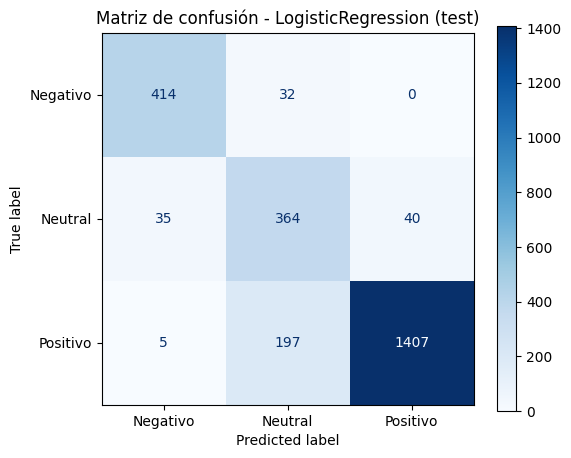

In [16]:
# Se genera la matriz de confusión del modelo final para el conjunto de test

cm = confusion_matrix(y_test, y_test_pred, labels=modelo_final.classes_)

fig_cm, ax_cm = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=modelo_final.classes_)
disp.plot(cmap="Blues", ax=ax_cm)
ax_cm.set_title(f"Matriz de confusión - {nombre_mejor} (test)")

with mlflow.start_run(run_id=run_ids[nombre_mejor]):
    mlflow.log_figure(fig_cm, "matriz_confusion_test.png")

plt.show()

🏃 View run LogisticRegression at: https://dagshub.com/Andres-viu-mbid/13MBID-AZ.mlflow/#/experiments/2/runs/3a1607064644449c9218817928476438
🧪 View experiment at: https://dagshub.com/Andres-viu-mbid/13MBID-AZ.mlflow/#/experiments/2


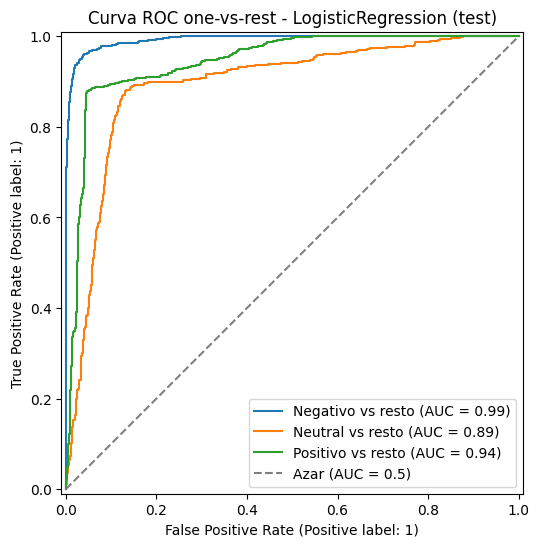

In [17]:
# Se genera la curva ROC (one-vs-rest) de cada clase para el modelo final en el conjunto de test

y_test_proba = modelo_final.predict_proba(X_test)

fig_roc, ax_roc = plt.subplots(figsize=(7, 6))
for i, clase in enumerate(modelo_final.classes_):
    RocCurveDisplay.from_predictions(
        (y_test == clase).astype(int),
        y_test_proba[:, i],
        name=f"{clase} vs resto",
        ax=ax_roc,
    )
ax_roc.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar (AUC = 0.5)")
ax_roc.set_title(f"Curva ROC one-vs-rest - {nombre_mejor} (test)")
ax_roc.legend(loc="lower right")

with mlflow.start_run(run_id=run_ids[nombre_mejor]):
    mlflow.log_figure(fig_roc, "curva_roc_test.png")

plt.show()

Exportación de los resultados de la comparación de modelos

In [18]:
df_resultados.to_csv("resultados_modelos.csv", index=False)